# 보배드림 구매 고민 글 분석

**질문: 차를 추천받으려는 사람에게 무엇을 물어봐야 하나?**

구매 고민 글의 댓글에서 사람들이 되묻는 질문("1년에 몇 km 타세요?", "애 있어요?")을 모아 빈도를 센다.
차를 아는 사람들이 추천 전에 묻는 것이 곧 물어야 할 질문 후보이고,
글쓴이가 본문에 이미 자주 적는 정보는 굳이 물을 필요가 없다.

- 데이터: `data/processed/bobaedream/2026-11-23.jsonl` (`scripts/crawl_bobaedream.py`로 수집)
- 범위: 국산차·수입차 게시판, 제목 검색어 11개, 2024년 이후 글

In [1]:
import json
import re

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({
    "font.family": "Malgun Gothic", "axes.unicode_minus": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e4e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.edgecolor": "#9a9893", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
BLUE, ORANGE = "#2a78d6", "#eb6834"

with open("data/processed/bobaedream/2026-11-23.jsonl", encoding="utf-8") as f:
    posts = pd.DataFrame([json.loads(line) for line in f])
posts["posted_at"] = pd.to_datetime(posts["posted_at"])
posts["body"] = posts["body"].fillna("")
print("수집한 글", len(posts))
posts = posts[posts["posted_at"] >= "2024-01-01"].reset_index(drop=True)
print("2024년 이후", len(posts))

수집한 글 3813
2024년 이후 3780


## 1. 수집 현황

목록 날짜에 연도가 없어 연도를 거꾸로 계산하다 어긋난 2024년 이전 글 몇 건은 위에서 뺐다.

board
national    3209
import       571
댓글 30,858개, 글당 중앙값 6개, 댓글 없는 글 107건


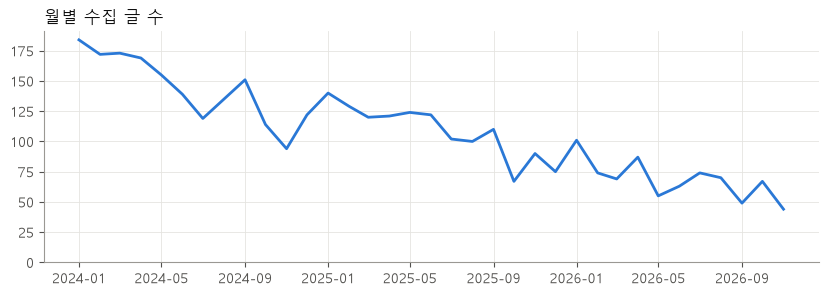

In [2]:
n_comments = posts["comments"].str.len()
print(posts["board"].value_counts().to_string())
print(f"댓글 {n_comments.sum():,}개, 글당 중앙값 {n_comments.median():.0f}개, 댓글 없는 글 {(n_comments == 0).sum()}건")

monthly = posts.set_index("posted_at").resample("MS").size()
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(monthly.index, monthly.values, color=BLUE, linewidth=2)
ax.set_title("월별 수집 글 수", loc="left")
ax.set_ylim(0)
plt.show()

## 2. 구매 고민 글 추리기

검색어("추천", "고민")에 걸린 글에는 "타이어 추천", "맛집 추천", "중고차 팔 때" 같은 글도 섞여 있다.
제목 규칙으로 **차를 고르는 중인 글**만 남긴다.

- 구매 의도: 제목에 추천·고민·조언·살까·구매·vs·첫차 등
- 차 맥락: 제목이나 본문 앞부분에 차종·예산·연료 등
- 제외: 용품·정비 관련(타이어, 썬팅, 블박 …), 구매 이후·판매 관련(출고, 환불, 팔려고 …)

규칙 기반이라 오분류가 있다. 아래 표본으로 정확도를 눈으로 확인한다.

In [3]:
INTENT = r"추천|고민|조언|살까|사려|살려|사고\s?싶|구매|구입|첫\s?차|입문|vs|골라|선택|어떤\s?차|어느\s?차|뭐\s?살|뭘\s?살|대차|교체|바꾸려|넘어가|어떨까|괜찮을까|어떤가요"
CAR = (r"차|suv|세단|경차|하이브리드|전기|디젤|가솔린|lpg|4륜|사륜|트럭|그랜[저져]|쏘나타|아반떼|\bk\d\b|카니발|쏘렌토|싼타페|"
       r"팰리세이드|투싼|스포티지|\bg\d0\b|\bgv\d0\b|bmw|벤츠|아우디|테슬라|제네시스|모델\s?[3ysx]|볼보|렉서스|토요타|혼다|"
       r"폭스바겐|미니|포르쉐|레이|모닝|캐스퍼|셀토스|코나|트레일블레이저|토레스|ev\d|아이오닉|만원|천만|예산")
OFF = (r"타이어|썬팅|틴팅|블랙박스|블박|네비|세차|코팅|광택|오일|정비|공업사|카센터|와이퍼|배터리|밧데리|하이패스|노래|영화|음악|"
       r"맛집|국밥|유산균|게임|mmorpg|주식|석유주|신발|런닝화|칼|가위|노트북|휴대폰|핸드폰|모니터|시계|여행|카메라|매트|시트커버|"
       r"방향제|용품|도색|도장|덴트|휠|스피커|앰프|충전기\s?설치|운전\s?연수|수동\s?운전|배우자|드라이브")
AFTER = (r"판매|팔[려았고까때]|매도|매입|환불|소송|계약서|사기|후기|샀습니다|샀어요|출고|인수|구매했|구입했|레몬법|고장|수리|"
         r"보험이력|사고이력|성능점검|이전비|취등록|등록지|흠집|기스|떨림|부식|딜러한테|주의\s?점|사는\s?법|정보\]|순위|엠블럼")

title = posts["title"].str.lower()
head = (posts["title"] + " " + posts["body"].str[:400]).str.lower()
posts["is_purchase"] = (title.str.contains(INTENT) & head.str.contains(CAR)
                        & ~title.str.contains(OFF) & ~title.str.contains(AFTER))
buy = posts[posts["is_purchase"]].reset_index(drop=True)
print(f"구매 고민 글 {len(buy):,}건 / 전체 {len(posts):,}건")

구매 고민 글 2,097건 / 전체 3,780건


In [4]:
print("[남긴 글 표본]")
print(buy["title"].sample(20, random_state=0).to_string(index=False))
print()
print("[뺀 글 표본]")
print(posts.loc[~posts["is_purchase"], "title"].sample(20, random_state=0).to_string(index=False))

[남긴 글 표본]
          쏘렌토 4세대 중고차 당신의 선택은 무엇입니까!
     니로 하이브리드 중고차 고민중입니다. 후보중 선택해주세요
더뉴그랜저ig 2.5가솔린 중고 구매 고민입니다 고견부탁드랴여ㅠㅠ
             중고차 구입 G80 VS G90 도와주세요
  언덕, 와인딩이 심한 출퇴근길 차량 추천 문의(왕복110km)
                   안녕하세요 첫 차 고민입니다 !
                쏘렌토 구매시 옵션 선택에 대한 고민
         중고차 구입후 차량 문제에 대한 조언을 구합니다.
           싼타페 mx5 신차 vs 싼타페 mx5 중고차
      중고차구매 질문- 업체인데 용도변경이 없는 건 뭘까요?
              RV차량 하체 전문가분 조언 부탁드립니다
        중고 제네시스 사고싶은데 고수님들 조언 부탁드립니다
                 중고차 하브 구입 조언 부탁드립니다
        신차 구입하려는데 가족이 타던차 주는거면 갈등생기죠
                 차린이 중고차 추천 부탁드려요.ㅜㅜ
    안녕하세요 중고차 구매하려는데 스포티지 더 볼드 어떤가요?
                    님들 첫차 아반떼 사고싶은데요
                     전기차 구매시 고려사항 정리
                           모닝중고차선택,.
        형님들...이중에서 최고의 패밀리세단 추천좀해줘요~

[뺀 글 표본]
         벤츠 GLC300 신차 구매했는데요 질문 좀..
         하이브리드 중고차사면 보증 못받는다는데 맞나요?
                     습식코팅제 추천부탁드립니다
            성게는 조회수랑 추천수가 넘사벽이군여 ㄷㄷ
                  오랜만에 고민한가지 털어봅니다.
                           중고차 성능보증
  너무 황당한 일(자동차 정비후 연료 누출

## 3. 조건 사전

글과 댓글에 나오는 조건을 주제별 정규식으로 잡는다. 같은 문장이 여러 주제에 걸릴 수 있다.
`agent-design.md`의 대화 에이전트 질문 항목(예산, 소득·월 여유, 용도, 탑승 인원, 보유 기간)도 이 안에 들어 있다.

In [5]:
TOPICS = {
    "예산": r"예산|\d+\s?만\s?원|\d+만원|\d+천|천만|\d억|가격대|총알|얼마\s?(까지|정도|생각)",
    "소득·재정": r"연봉|월급|소득|수입|실수령|외벌이|맞벌이|자산|모아\s?둔|저축|대출|빚|생활비|고정\s?지출",
    "결제 방식": r"할부|현금|리스|장기\s?렌트|렌트|일시불|금리|선수금|선납|무이자",
    "주행거리": r"주행\s?거리|연간|1년에|일년에|년에\s?\d|월에\s?\d|하루에|\d+\s?(km|키로|킬로)|만\s?키로|왕복|편도|많이\s?타|적게\s?타",
    "주행 환경": r"출퇴근|통근|장거리|단거리|시내|고속도로|국도|시골|산길|눈길|오프로드",
    "용도": r"용도|캠핑|차박|레저|업무용|영업용|출장|세컨|주말|낚시|골프",
    "가족·탑승 인원": r"가족|아이|애기|아기|애가|애\s?둘|와이프|아내|남편|부모님|탑승|\d인승|카시트|유모차|결혼|미혼|신혼|자녀|육아|임신|출산|혼자\s?(타|탈)",
    "주차·차 크기": r"주차|지하\s?주차장|기계식|골목|차폭|전장|크기|사이즈|소형|중형|대형|준중형|준대형",
    "연료·충전": r"충전|완속|급속|전기차|하이브리드|하브|디젤|가솔린|휘발유|lpg|연료",
    "보유 기간": r"보유|오래\s?(탈|타)|몇\s?년\s?(탈|타)|\d+\s?년\s?(이상\s?)?(탈|타)|평생|폐차\s?(까지|할\s?때)|탈\s?생각",
    "신차/중고": r"신차|중고|새\s?차|인증\s?중고|출고",
    "나이·경력": r"\d{2}\s?살|\d0대|나이|사회\s?초년생|초보|운전\s?경력|장롱|면허",
    "현재 차량": r"타던|지금\s?타는|현재\s?타|기존\s?차|타고\s?있|처분|팔고|대차|내\s?차는",
    "선호: 성능·승차감": r"승차감|성능|출력|가속|마력|정숙|소음|하체|핸들링|주행감|펀\s?카",
    "선호: 디자인·브랜드": r"디자인|외관|이쁘|예쁘|멋|브랜드|하차감|수입차|국산차|감성",
    "선호: 연비·유지비": r"연비|유지비|보험료|자동차세|감가|잔존|기름값|유류비",
    "선호: 공간·옵션·안전": r"공간|트렁크|2열|3열|실내|옵션|편의\s?사양|안전|ADAS|크루즈|통풍|열선",
}
TOPIC_RE = {k: re.compile(v, re.I) for k, v in TOPICS.items()}

def topics_in(text):
    return [k for k, r in TOPIC_RE.items() if r.search(text or "")]

## 4. 글쓴이가 본문에서 먼저 밝히는 조건

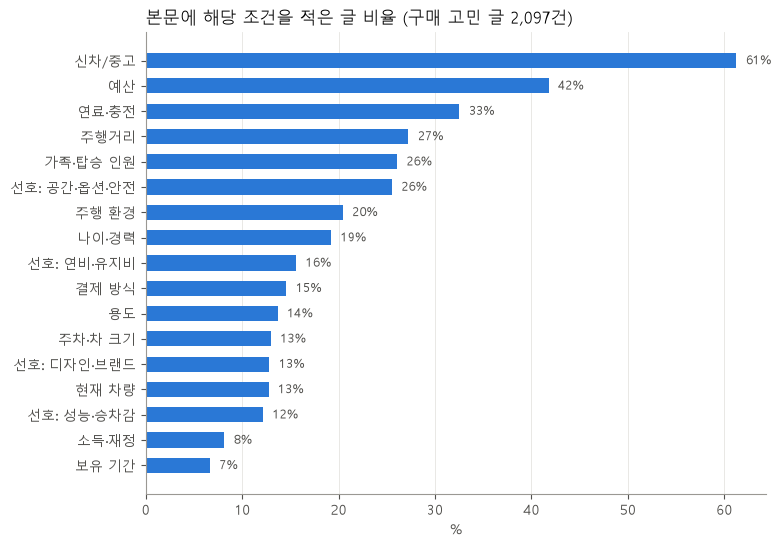

In [6]:
buy["body_topics"] = (buy["title"] + "\n" + buy["body"]).map(topics_in)
body_rate = pd.Series({k: buy["body_topics"].map(lambda t: k in t).mean() for k in TOPICS}).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(body_rate.index, body_rate.values * 100, color=BLUE, height=0.6)
for y, v in enumerate(body_rate.values):
    ax.text(v * 100 + 1, y, f"{v:.0%}", va="center", fontsize=9, color="#52514e")
ax.set_title(f"본문에 해당 조건을 적은 글 비율 (구매 고민 글 {len(buy):,}건)", loc="left")
ax.set_xlabel("%")
ax.grid(axis="y", visible=False)
plt.show()

## 5. 댓글은 무엇을 근거로 추천하나

글쓴이가 아닌 사람의 댓글에 나오는 조건을 글 단위로 센다(한 글에서 여러 번 나와도 1번).
추천하는 사람이 판단 근거로 끌어오는 조건이다.

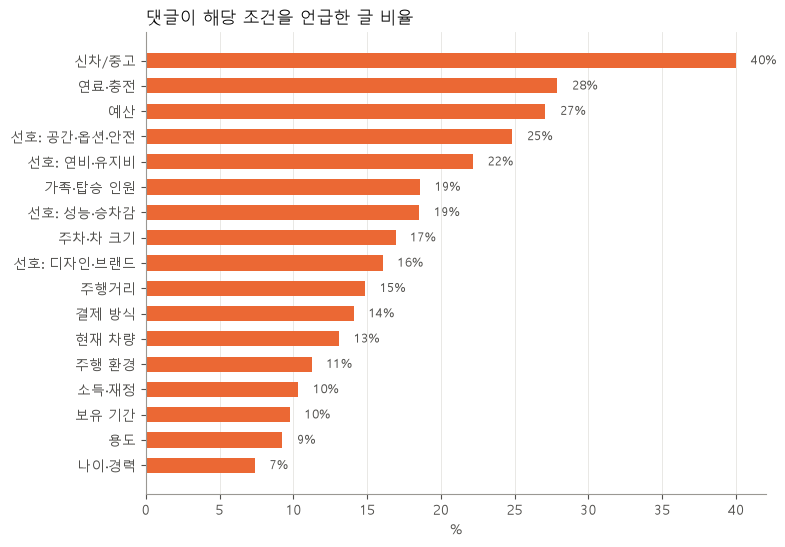

In [7]:
def comment_topics(comments):
    found = set()
    for c in comments:
        if not c["is_op"]:
            found.update(topics_in(c["text"]))
    return found

buy["comment_topics"] = buy["comments"].map(comment_topics)
comment_rate = pd.Series({k: buy["comment_topics"].map(lambda t: k in t).mean() for k in TOPICS}).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(comment_rate.index, comment_rate.values * 100, color=ORANGE, height=0.6)
for y, v in enumerate(comment_rate.values):
    ax.text(v * 100 + 1, y, f"{v:.0%}", va="center", fontsize=9, color="#52514e")
ax.set_title("댓글이 해당 조건을 언급한 글 비율", loc="left")
ax.set_xlabel("%")
ax.grid(axis="y", visible=False)
plt.show()

## 6. 질문 후보: 본문에 없는데 댓글이 꺼낸 조건

핵심 지표는 **본문에 그 조건이 없는 글 중 댓글이 그 조건을 꺼낸 비율**이다.
- 이 비율이 높다 → 글쓴이가 빠뜨려도 추천하는 사람이 끌어온다 → 에이전트가 먼저 물어야 할 후보
- 본문 언급률이 높다 → 사용자가 알아서 말한다 → 묻기보다 대화에서 뽑으면 된다

In [8]:
summary = []
for k in TOPICS:
    in_body = buy["body_topics"].map(lambda t: k in t)
    in_cmt = buy["comment_topics"].map(lambda t: k in t)
    summary.append({
        "주제": k,
        "본문 언급률": in_body.mean(),
        "댓글 언급률": in_cmt.mean(),
        "본문에 없을 때 댓글이 꺼낸 비율": in_cmt[~in_body].mean() if (~in_body).any() else 0,
    })
summary = pd.DataFrame(summary).set_index("주제").sort_values("본문에 없을 때 댓글이 꺼낸 비율", ascending=False)
summary.style.format("{:.1%}").bar(subset=["본문에 없을 때 댓글이 꺼낸 비율"], color="#f6b89c")

,본문 언급률,댓글 언급률,본문에 없을 때 댓글이 꺼낸 비율
주제,,,
신차/중고,61.2%,40.0%,26.8%
선호: 공간·옵션·안전,25.5%,24.8%,19.4%
예산,41.8%,27.1%,17.9%
선호: 연비·유지비,15.6%,22.2%,17.6%
선호: 성능·승차감,12.2%,18.6%,15.9%
연료·충전,32.5%,27.9%,15.5%
주차·차 크기,13.0%,16.9%,14.2%
선호: 디자인·브랜드,12.8%,16.1%,13.7%
가족·탑승 인원,26.0%,18.6%,11.2%


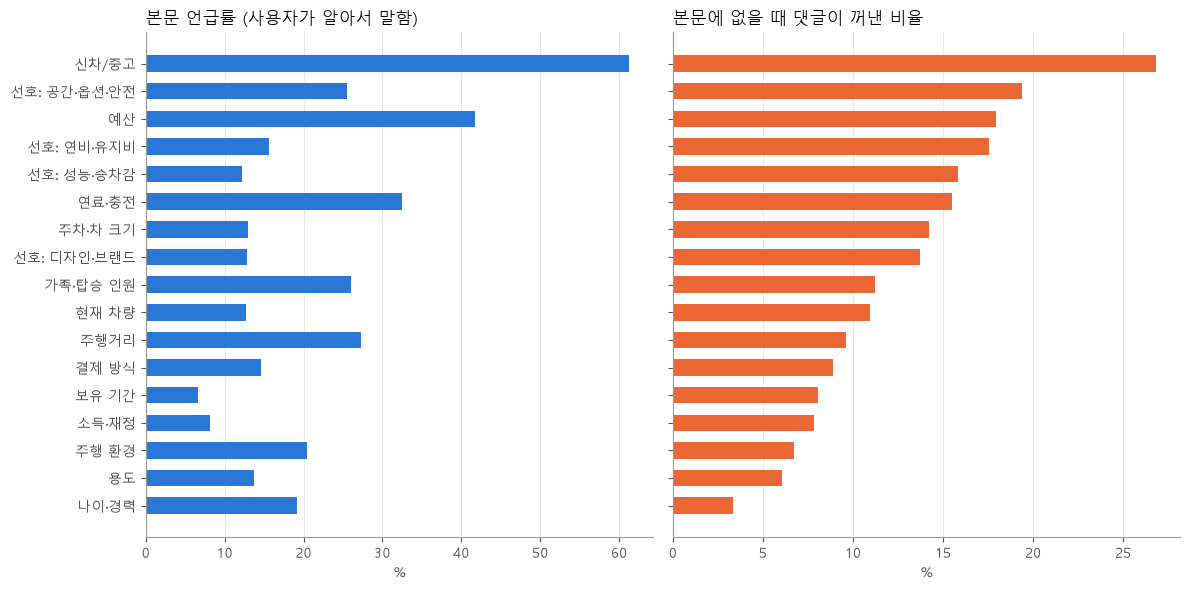

In [9]:
order = summary.index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
axes[0].barh(order, summary.loc[order, "본문 언급률"] * 100, color=BLUE, height=0.6)
axes[0].set_title("본문 언급률 (사용자가 알아서 말함)", loc="left")
axes[1].barh(order, summary.loc[order, "본문에 없을 때 댓글이 꺼낸 비율"] * 100, color=ORANGE, height=0.6)
axes[1].set_title("본문에 없을 때 댓글이 꺼낸 비율", loc="left")
for ax in axes:
    ax.set_xlabel("%")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 7. 댓글의 되묻기

글쓴이 상황을 직접 묻는 댓글 문장만 따로 본다.
- 질문 문장: `?`로 끝나거나 `나요/까요/가요/니까/는지요`로 끝남
- 되묻기: 그중 `~시나요`, `~실 건가요`, `얼마나`, `몇 년`, `예산이` 같은 상황 질문 표현이 있고,
  `~않을까요`, `~어떠세요`, `굳이`처럼 제안·반어 표현이 없는 문장

보배드림 댓글은 묻기보다 바로 의견을 다는 경우가 대부분이라 되묻기는 적다. 빈도보다 실제 문장을 읽는 용도로 쓴다.

In [10]:
Q_END = re.compile(r"(\?|나요|까요|가요|니까|는지요|냐)\s*[.~!ㅠㅜㅎㅋ]*$")
ASK = re.compile(r"시나요|십니까|신가요|실\s?(?:건가요|거|예정|생각)|하시|타시|있으세요|있으신|되시|되나요|되세요|얼마나|"
                 r"몇\s?(?:년|명|km|키로|살|인|대|만)|언제|어떤\s?용도|무슨\s?용도|예산|애\s?있|아이\s?있")
SUGGEST = re.compile(r"않을까요|않나요|않습니까|아닌가요|아닐까요|아님\?|낫지|낫나요|나을까요|어떨까요|어떻습니까|어떠세요|"
                     r"어떠신|어때요|어떤가요|좋을듯|ㅋㅋ|굳이|왜")

def question_sentences(text):
    parts = re.split(r"(?<=[?.!])\s+|\n", text or "")
    return [p.strip() for p in parts if p.strip() and Q_END.search(p.strip())]

rows = [{"post_id": p["id"], "question": q, "topics": topics_in(q)}
        for _, p in buy.iterrows() for c in p["comments"] if not c["is_op"]
        for q in question_sentences(c["text"])]
questions = pd.DataFrame(rows)
asks = questions[questions["question"].str.contains(ASK) & ~questions["question"].str.contains(SUGGEST)]
print(f"질문 문장 {len(questions):,}개 → 되묻기로 추린 문장 {len(asks):,}개 (글 {asks['post_id'].nunique():,}건)")
print()
print(asks["question"].sample(30, random_state=3).to_string(index=False))

질문 문장 1,886개 → 되묻기로 추린 문장 107개 (글 103건)

                         또한 엔진을 전체 교환하시는지 아님 엔진 위 헤드만 교환하시는지요?
                        타이밍 손보는김에 누유 하체 부싱까지 싹 갈아봐야 얼마나 나올까요..
                                              차량 가격은 얼마나 하는지요?
                2번 선택하면 1번차량이 교체한 부품들 언제가 되었던 문제가 될 소지가 많으니까요.
                  보통 하브관련 보증은 10년에20만키로일텐데 신차 수리비걱정을 벌써부터 하시나요
                                                타이어회사 인수하시려고예?
                                   15년 20만킬로 뛴차에 어떤컨디션을 원하시나요?
                        그런상황에서 그 가격의 차이를 극복 하는데 시간이 얼마나 걸리는냐 ?
                                    이번에 Q5도 예쁘던데, SUV는 별로신가요??
                                   수입 중고차를 첫 차량으로 시작하시는건가요...?
                                                     안사면 안되나요?
                                                     예산이 얼마에요?
                                             이 차량은 얼마나 타시는겁니까?
                                                마트가실거면 경차 가시죠?
                                         마음이 GV 인데 무얼 고민하시나요.?
              

In [11]:
(asks.explode("topics").dropna().groupby("topics")["post_id"].nunique()
     .sort_values(ascending=False).rename("되묻기가 나온 글 수").to_frame())

,되묻기가 나온 글 수
topics,
예산,15
신차/중고,8
결제 방식,5
가족·탑승 인원,4
연료·충전,4
선호: 연비·유지비,4
선호: 성능·승차감,3
주행 환경,3
주행거리,3


## 8. 글쓴이가 댓글로 덧붙이는 정보

댓글에 답하면서 글쓴이가 추가로 밝히는 조건. 본문에서 빠뜨리기 쉬운 정보다.

In [12]:
op = [{"post_id": p["id"], "topics": topics_in(c["text"])}
      for _, p in buy.iterrows() for c in p["comments"] if c["is_op"]]
op = pd.DataFrame(op)
print(f"글쓴이 댓글 {len(op):,}개, 글쓴이가 댓글을 단 글 {op['post_id'].nunique():,}건")
(op.explode("topics").dropna().groupby("topics")["post_id"].nunique()
   .sort_values(ascending=False).rename("글쓴이가 댓글에서 밝힌 글 수").to_frame())

글쓴이 댓글 4,369개, 글쓴이가 댓글을 단 글 1,265건


,글쓴이가 댓글에서 밝힌 글 수
topics,
신차/중고,207
예산,168
연료·충전,164
가족·탑승 인원,119
선호: 공간·옵션·안전,119
선호: 연비·유지비,101
주차·차 크기,90
선호: 디자인·브랜드,87
선호: 성능·승차감,77


## 9. agent-design.md 질문 항목과 비교

| agent-design 항목 | 대응 주제 |
|---|---|
| 예산 | 예산 |
| 소득·월 여유 | 소득·재정 |
| 용도 | 용도, 주행 환경 |
| 탑승 인원 | 가족·탑승 인원 |
| 보유 기간 | 보유 기간 |
| 주행거리·가격·연식 (선택값) | 주행거리, 예산, 신차/중고 |

In [13]:
design = {"예산": ["예산"], "소득·월 여유": ["소득·재정"], "용도": ["용도", "주행 환경"],
          "탑승 인원": ["가족·탑승 인원"], "보유 기간": ["보유 기간"]}
in_design = {t for ts in design.values() for t in ts}
view = summary.copy()
view["agent-design에 있음"] = ["O" if k in in_design else "" for k in view.index]
view.style.format("{:.1%}", subset=["본문 언급률", "댓글 언급률", "본문에 없을 때 댓글이 꺼낸 비율"])

,본문 언급률,댓글 언급률,본문에 없을 때 댓글이 꺼낸 비율,agent-design에 있음
주제,,,,
신차/중고,61.2%,40.0%,26.8%,
선호: 공간·옵션·안전,25.5%,24.8%,19.4%,
예산,41.8%,27.1%,17.9%,O
선호: 연비·유지비,15.6%,22.2%,17.6%,
선호: 성능·승차감,12.2%,18.6%,15.9%,
연료·충전,32.5%,27.9%,15.5%,
주차·차 크기,13.0%,16.9%,14.2%,
선호: 디자인·브랜드,12.8%,16.1%,13.7%,
가족·탑승 인원,26.0%,18.6%,11.2%,O


## 10. 자주 나오는 단어

형태소 분석기 [Kiwi](https://github.com/bab2min/kiwipiepy)로 명사(일반·고유)와 영문 단어를 뽑아 센다.
- 글 단위로 센다(한 글에서 여러 번 나와도 1번). 댓글은 한 글의 댓글 전체를 하나로 본다.
- 모델명·줄임말(GV70, 하브 등)은 쪼개지지 않게 사용자 사전에 넣었다.
- 모든 글에 다 나오는 말(차, 고민, 추천, 부탁 …)과 뜻이 없는 말(이상, 가능, 필요 …)은 불용어로 뺐다.
- 같은 뜻의 표기는 합쳤다: 중고차→중고, 하브→하이브리드, 그랜져→그랜저, 새차→신차.

워드클라우드는 인상을 보는 용도이고, 정확한 빈도는 옆의 막대그래프로 읽는다.

In [14]:
from collections import Counter

from kiwipiepy import Kiwi
from wordcloud import WordCloud

kiwi = Kiwi()
USER_WORDS = ["하브", "하이브리드", "전기차", "중고차", "신차", "첫차", "경차", "세컨카", "패밀리카", "인증중고",
              "사회초년생", "승차감", "하차감", "유지비", "감가", "차박", "풀옵", "깡통", "독삼사", "국산차", "수입차",
              "GV60", "GV70", "GV80", "G70", "G80", "G90", "K3", "K5", "K7", "K8", "K9",
              "EV3", "EV4", "EV5", "EV6", "EV9", "아이오닉5", "아이오닉6", "모델3", "모델Y",
              "X3", "X5", "X7", "GLC", "GLE", "E클래스", "C클래스", "S클래스", "XC60", "XC90"]
for w in USER_WORDS:
    kiwi.add_user_word(w, "NNP", 0)

STOP = set("""
차 차량 고민 추천 부탁 생각 정도 구매 구입 질문 문의 형님 형님들 안녕 감사 선배 선배님 선배님들 조언 사람 지금 이번 경우
때문 정말 그냥 진짜 혹시 여기 저희 글 말씀 의견 고견 도움 선택 이유 문제 상황 얘기 이야기 다음 처음 요즘 나중 하나 두 개
쪽 분 님 거 것 수 등 중 때 년 월 일 원 만원 천 정 좀 더 걱정 마음 자동차 어르신 어르신들 행님 행님들 국게 보배 회원
이상 가능 필요 차이 개인 관련 본인 대부분 자체 조금 사항 내용 아래 마지막 최근 기준 이용 진행 포함 사이 시작 정상 일반 입장
부분 전화 방문 사진 변경 결과 시간 확인 정보 사용 가지 하루 자기 이후 이전 동안 그거 이거 저거 무엇 어디 누구 모두 전부
""".split())

NORMALIZE = {"중고차": "중고", "하브": "하이브리드", "그랜져": "그랜저", "키로": "KM", "새차": "신차"}

def nouns(text):
    words = []
    for t in kiwi.tokenize(text or ""):
        if t.tag in ("NNG", "NNP") or (t.tag == "SL" and len(t.form) >= 2):
            w = t.form.upper() if t.tag == "SL" else t.form
            w = NORMALIZE.get(w, w)
            if len(w) >= 2 and w not in STOP:
                words.append(w)
    return words

body_df = Counter(w for text in (buy["title"] + "\n" + buy["body"]) for w in set(nouns(text)))
comment_text = buy["comments"].map(lambda cs: "\n".join(c["text"] or "" for c in cs if not c["is_op"]))
comment_df = Counter(w for text in comment_text for w in set(nouns(text)))
print(f"본문 단어 종류 {len(body_df):,}개, 댓글 단어 종류 {len(comment_df):,}개")

본문 단어 종류 7,695개, 댓글 단어 종류 10,784개


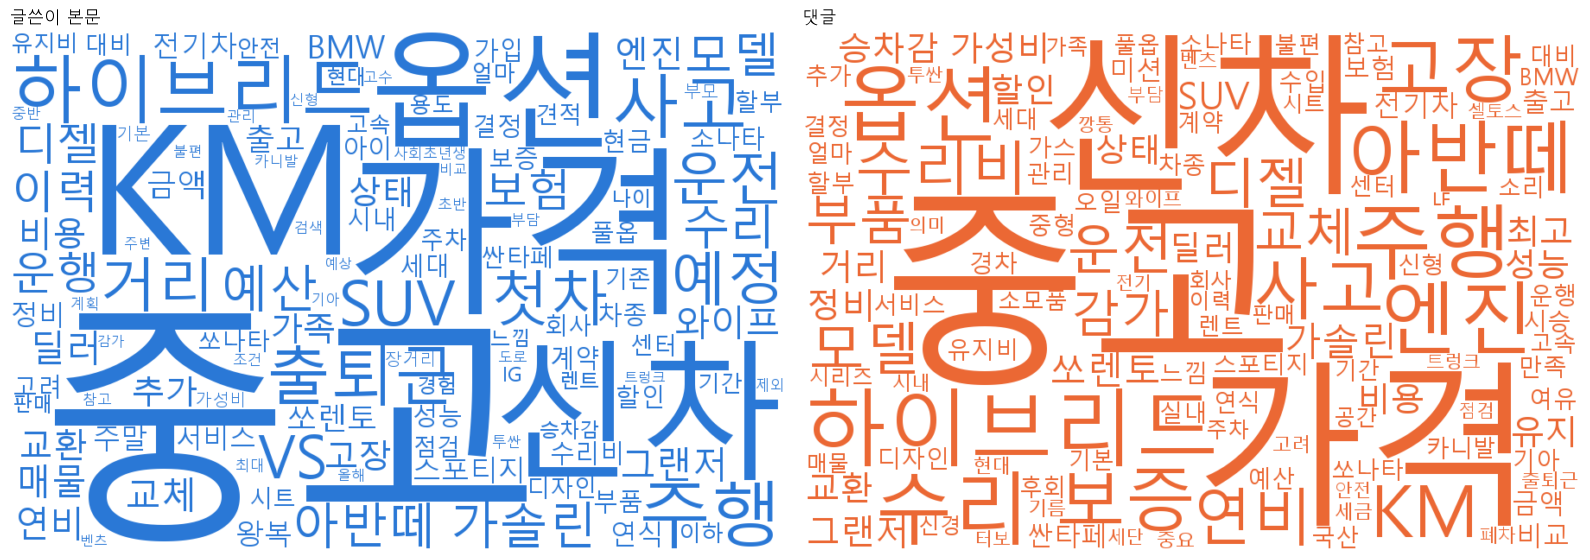

In [15]:
FONT = "C:/Windows/Fonts/malgun.ttf"

def one_color(hex_color):
    return lambda *args, **kwargs: hex_color

def draw(ax, freq, color, title):
    wc = WordCloud(font_path=FONT, width=900, height=600, background_color="white",
                   max_words=120, prefer_horizontal=1.0, color_func=one_color(color), random_state=0)
    ax.imshow(wc.generate_from_frequencies(dict(freq.most_common(120))), interpolation="bilinear")
    ax.set_title(title, loc="left")
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
draw(axes[0], body_df, BLUE, "글쓴이 본문")
draw(axes[1], comment_df, ORANGE, "댓글")
plt.tight_layout()
plt.show()

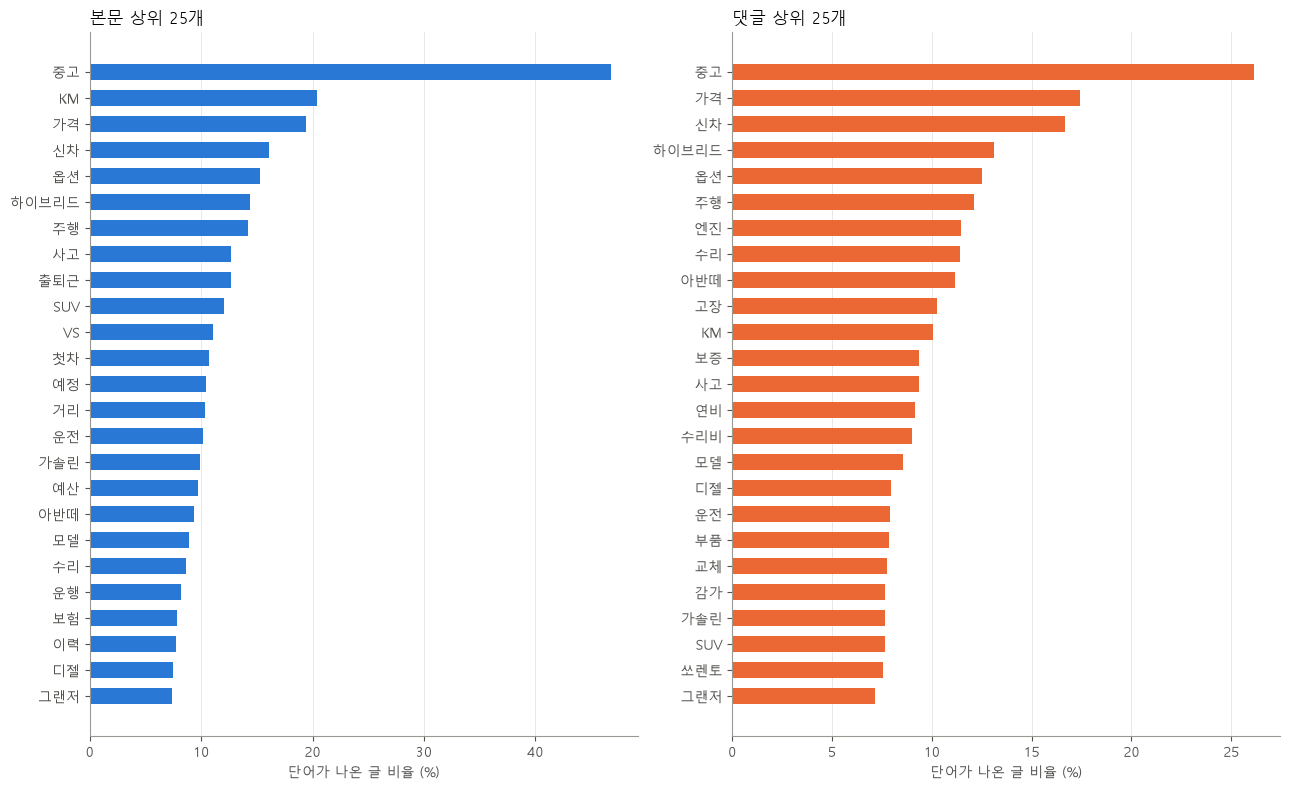

In [16]:
def top_bar(ax, freq, color, title, n=25):
    words, counts = zip(*freq.most_common(n))
    rates = [c / len(buy) * 100 for c in counts]
    ax.barh(words[::-1], rates[::-1], color=color, height=0.6)
    ax.set_title(title, loc="left")
    ax.set_xlabel("단어가 나온 글 비율 (%)")
    ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 8))
top_bar(axes[0], body_df, BLUE, "본문 상위 25개")
top_bar(axes[1], comment_df, ORANGE, "댓글 상위 25개")
plt.tight_layout()
plt.show()

### 댓글에서 유독 많이 나오는 단어

본문 대비 댓글에서 상대적으로 더 자주 나오는 단어. 추천하는 사람이 끌어오는 관점이다.
두 쪽 모두 글 20건 이상에 나온 단어만 비교한다.

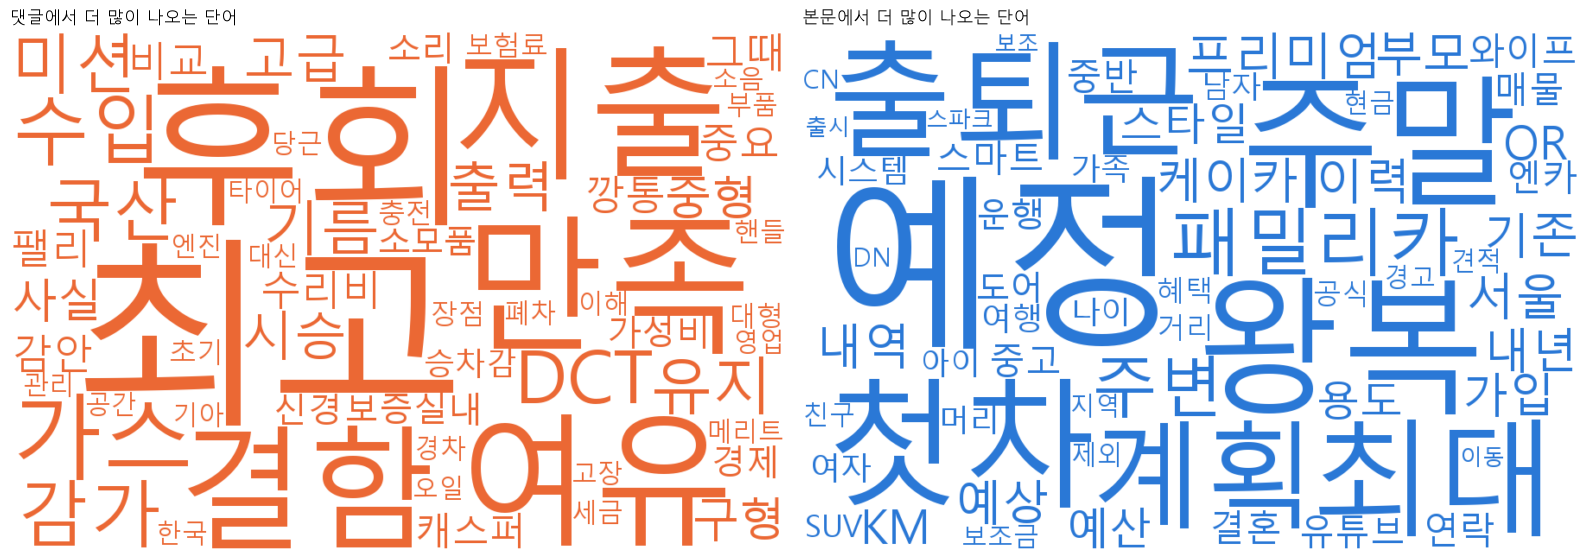

,본문 비율,댓글 비율,댓글/본문
최고,1.0%,6.6%,6.3배
후회,1.0%,4.5%,4.5배
만족,1.7%,5.4%,3.3배
여유,1.7%,5.0%,3.0배
지출,1.0%,2.8%,3.0배
결함,1.0%,3.1%,2.9배
가스,1.8%,5.1%,2.9배
수입,1.7%,4.6%,2.7배
DCT,1.3%,3.3%,2.6배
감가,3.1%,7.7%,2.4배


In [17]:
words = [w for w in set(body_df) | set(comment_df) if body_df[w] + comment_df[w] >= 40 and min(body_df[w], comment_df[w]) >= 20]
lift = pd.DataFrame({
    "본문 비율": [body_df[w] / len(buy) for w in words],
    "댓글 비율": [comment_df[w] / len(buy) for w in words],
}, index=words)
lift["댓글/본문"] = lift["댓글 비율"] / lift["본문 비율"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
draw(axes[0], Counter(lift["댓글/본문"].nlargest(60).to_dict()), ORANGE, "댓글에서 더 많이 나오는 단어")
draw(axes[1], Counter((1 / lift["댓글/본문"]).nlargest(60).to_dict()), BLUE, "본문에서 더 많이 나오는 단어")
plt.tight_layout()
plt.show()

lift.sort_values("댓글/본문", ascending=False).head(20).style.format({"본문 비율": "{:.1%}", "댓글 비율": "{:.1%}", "댓글/본문": "{:.1f}배"})

**읽는 법**
- 본문 쪽(파랑)은 *상황* 단어가 많다: 첫차, 사회초년생, 출퇴근, 왕복, 주말, 패밀리카, 와이프, 결혼, 예정·계획.
  글쓴이는 자기 처지와 계획을 설명한다.
- 댓글 쪽(주황)은 *결과와 비용* 단어가 많다: 후회, 만족, 결함, 지출, 여유, 감가, 유지, 기름, 보험료, 미션·DCT.
  추천하는 사람은 "사고 나서 후회하지 않을지", "감당할 수 있는지"를 따진다.
- 즉 사용자는 상황을 말하고, 조언자는 유지비·결함·감가 같은 장기 비용과 리스크로 답한다.
  6절의 "본문에 없을 때 댓글이 꺼낸 조건"(연비·유지비, 성능)과 같은 방향이다.

## 11. 정리

수치는 정규식 분류 기준이라 대략적인 크기로 읽는다.

1. **사용자가 알아서 말하는 것**: 신차/중고(61%), 예산(42%), 연료(33%), 주행거리(27%), 가족·탑승 인원(26%).
   이 항목들은 먼저 묻기보다 첫 메시지에서 뽑아내고, 빠졌을 때만 물으면 된다.
2. **댓글이 본문보다 자주 꺼내는 것**: 연비·유지비, 성능·승차감, 주차·차 크기, 디자인·브랜드, 공간·옵션.
   사용자는 잘 안 쓰는데 추천하는 사람은 판단 근거로 쓰는 조건이다.
   agent-design.md의 "모델 수준 니즈"에 해당하고, 대화 에이전트 질문 목록에는 없다.
3. **소득·재정과 보유 기간은 본문에도 댓글에도 드물다**(각 10% 안팎).
   agent-design.md는 둘 다 묻도록 되어 있다. 커뮤니티에서는 거의 다루지 않는 축이라, 묻는다면 왜 묻는지 설명이 필요하다.
4. **직접 되묻는 댓글은 적다**(구매 고민 글의 약 5%). 그중에서는 예산을 묻는 경우가 가장 많다.
   "무엇을 물어야 하나"는 되묻기보다 2번처럼 댓글이 근거로 드는 조건에서 찾는 편이 데이터가 많다.

## 12. 한계

- 구매 고민 글 판별과 주제 분류가 모두 정규식이라 오분류가 있다. 표본으로 확인한 정도의 정확도로 읽어야 한다.
- "댓글이 꺼낸 비율"은 댓글이 그 조건을 언급했다는 뜻이지 꼭 질문했다는 뜻은 아니다. 되묻기 판별(7절)도 문장 표현만 본다.
- 댓글이 100개를 넘는 글은 앞 100개만 수집했다.
- 보배드림 이용자(30~50대 남성 비중이 높은 자동차 커뮤니티)의 시각이다. 첫 차를 사는 사람이 실제로 궁금해하는 것과는 다를 수 있다.
- 정확도를 높이려면 LLM으로 글과 질문을 분류하는 단계를 추가하면 된다.